# RQ5 — When does redundancy control dominate homology separation?

## Scientific question

**Across the full generalization landscape, when is predictive performance controlled primarily by redundancy reduction (`R`), when by train–test homology separation (`S`), and how much of that apparent dominance can be related to changes in training-data quantity versus split topology?**

RQ2 established that `R` removes large amounts of redundant evidence while preserving predictive performance unevenly across tasks and representations.  
RQ3 established that `S` produces a smaller global penalty whose magnitude collapses under strict `R`.  
RQ4 established that `R` and `S` are non-additive.

RQ5 now asks **which factor is the dominant driver of generalization loss, where that dominance changes, and whether a single “R matters more than S” statement is scientifically defensible.**

### Core questions

1. Is `R` globally a stronger driver than `S`?
2. How often is a surface R-dominant, balanced, or S-dominant?
3. Does the answer change by task, representation, or learner?
4. Does the answer change depending on where the other factor is fixed?
5. How often does the apparent dominant factor **flip** across the same 4×4 surface?
6. Is factor dominance preserved with AP skill / macro-F1?
7. How much of the R effect tracks training-entity loss?
8. How much of the S effect occurs while train/test size remains essentially unchanged?
9. Does S sensitivity track changes in cluster granularity more strongly than sample-size drift?
10. Can we separate **evidence-removal dominance** from **evaluation-topology dominance**?

> This notebook is descriptive and factorial. Bootstrap uncertainty and common-test paired sensitivity remain reserved for their dedicated RQs.

## Interpretation contract

`R` and `S` are not interchangeable biological quantities.

- `R` changes the available sequence universe before splitting.
- `S` changes the homology structure of the train/test partition at fixed R.

Therefore a direct comparison of their predictive effects is meaningful as a comparison of **protocol/generalization drivers**, not as a claim that “30% redundancy” and “30% homology separation” are physically equivalent perturbations.

We use multiple complementary dominance definitions so that conclusions do not depend on one arbitrary statistic.

In [1]:
from pathlib import Path
from itertools import combinations
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 350)
pd.set_option("display.width", 240)
pd.set_option("display.max_rows", 350)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

R_PAIRS = list(combinations(R_LEVELS, 2))
S_PAIRS = list(combinations(S_LEVELS, 2))
ADJ_R_PAIRS = [(90, 70), (70, 50), (50, 30)]
ADJ_S_PAIRS = [(90, 70), (70, 50), (50, 30)]

TASK_PATHS = {
    "global_easy": "global_easy",
    "global_hard": "global_hard",
    "global_mixed": "global_mixed",
    "subtype_endolysin": "subtype_binary/endolysin",
    "subtype_depolymerase": "subtype_binary/depolymerase",
    "subtype_val": "subtype_binary/virion_associated_lytic_enzyme",
    "multiclass_clean": "multiclass_clean",
}

BINARY_TASKS = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
]

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a").is_dir()
            and (candidate / "results/analysis_supervised/stage12b").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate project root containing Stage12A and Stage12B."
    )

ROOT = find_project_root()
STAGE12A = ROOT / "results/analysis_supervised/stage12a"
STAGE12B = ROOT / "results/analysis_supervised/stage12b"
PREDICTIVE_ROOT = ROOT / "data/predictive_universe"
CACHE_DIR = ROOT / "results/analysis_supervised/notebook_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)

ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass


In [2]:
master = pd.read_csv(
    STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

r_deltas = pd.read_csv(
    STAGE12B / "rs_redundancy_deltas_fixed_S.tsv",
    sep="\t",
    low_memory=False,
)

s_deltas = pd.read_csv(
    STAGE12B / "rs_split_deltas_fixed_R.tsv",
    sep="\t",
    low_memory=False,
)

interactions = pd.read_csv(
    STAGE12B / "rs_all_interaction_rectangles.tsv",
    sep="\t",
    low_memory=False,
)

print("Experiment families:", len(master))
print("Tasks:", sorted(master["task"].unique()))
print("Representations:", sorted(master["representation"].unique()))
print("Algorithms:", sorted(master["algorithm"].unique()))

coverage = (
    master.groupby(["task", "representation", "algorithm"])
    .size()
    .rename("n_cells")
    .reset_index()
)

display(coverage["n_cells"].value_counts().sort_index().to_frame("n_surfaces"))
assert coverage["n_cells"].eq(16).all(), "Incomplete R×S surface detected."

Experiment families: 2240
Tasks: ['global_easy', 'global_hard', 'global_mixed', 'multiclass_clean', 'subtype_depolymerase', 'subtype_endolysin', 'subtype_val']
Representations: ['esm2_t30_150m', 'esm2_t6_8m', 'onehot_1024', 'roxy_48']
Algorithms: ['KNN', 'LR', 'MLP', 'RF', 'XGB']


,n_surfaces
n_cells,
16,140


## 1. Add prevalence-normalized AP skill

In [3]:
def detect_prevalence(df):
    for c in [
        "test_prevalence",
        "prevalence",
        "positive_prevalence",
        "class_prevalence",
    ]:
        if c in df.columns:
            return pd.to_numeric(df[c], errors="coerce"), c

    if {"n_positive", "n_test"} <= set(df.columns):
        return (
            pd.to_numeric(df["n_positive"], errors="coerce")
            / pd.to_numeric(df["n_test"], errors="coerce")
        ), "derived_from_n_positive_n_test"

    if {"tp", "fn", "tn", "fp"} <= set(df.columns):
        pos = (
            pd.to_numeric(df["tp"], errors="coerce")
            + pd.to_numeric(df["fn"], errors="coerce")
        )
        n = (
            pos
            + pd.to_numeric(df["tn"], errors="coerce")
            + pd.to_numeric(df["fp"], errors="coerce")
        )
        return pos / n, "derived_from_confusion_counts"

    return pd.Series(np.nan, index=df.index), None

prev, prev_source = detect_prevalence(master)
master["prevalence_for_ap"] = prev

if "ap" in master.columns:
    denom = 1.0 - master["prevalence_for_ap"]
    master["ap_skill"] = np.where(
        denom > 0,
        (master["ap"] - master["prevalence_for_ap"]) / denom,
        np.nan,
    )

print("Prevalence source:", prev_source)
print("AP skill finite:", master["ap_skill"].notna().sum() if "ap_skill" in master.columns else 0)

Prevalence source: prevalence
AP skill finite: 1920


# 2. Surface-level dominance: robust extreme-span definition

For each `task × representation × algorithm` surface:

\[
E_R =
\mathrm{median}_{S}
\left|
M(R30,S)-M(R90,S)
\right|
\]

\[
E_S =
\mathrm{median}_{R}
\left|
M(R,S30)-M(R,S90)
\right|
\]

Define the normalized dominance index:

\[
D =
\frac{E_R-E_S}{E_R+E_S}.
\]

Properties:

- `D = +1`: purely R-driven;
- `D = 0`: balanced;
- `D = -1`: purely S-driven.

The median across conditioning levels makes this less sensitive to a single unusual row/column.

In [4]:
surface_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "algorithm"]
):
    task, rep, alg = keys

    surface = (
        grp.pivot_table(
            index="R",
            columns="S",
            values="mcc",
            aggfunc="first",
        )
        .reindex(index=R_LEVELS, columns=S_LEVELS)
    )

    if surface.isna().any().any():
        continue

    r_effects = {
        s: float(surface.loc[30, s] - surface.loc[90, s])
        for s in S_LEVELS
    }

    s_effects = {
        r: float(surface.loc[r, 30] - surface.loc[r, 90])
        for r in R_LEVELS
    }

    E_R = float(np.median(np.abs(list(r_effects.values()))))
    E_S = float(np.median(np.abs(list(s_effects.values()))))

    D = (
        (E_R - E_S) / (E_R + E_S)
        if (E_R + E_S) > 0
        else np.nan
    )

    surface_rows.append(
        {
            "task": task,
            "representation": rep,
            "algorithm": alg,
            "R_effect_abs_median": E_R,
            "S_effect_abs_median": E_S,
            "dominance_index": D,
            "R_to_S_abs_ratio": (
                E_R / E_S if E_S > 0 else np.inf
            ),
            "R_effect_signed_median": np.median(list(r_effects.values())),
            "S_effect_signed_median": np.median(list(s_effects.values())),
            **{f"R_effect_at_S{s}": v for s, v in r_effects.items()},
            **{f"S_effect_at_R{r}": v for r, v in s_effects.items()},
        }
    )

surface_dominance = pd.DataFrame(surface_rows)

print("Surfaces:", len(surface_dominance))
display(surface_dominance.head())

Surfaces: 140


,task,representation,algorithm,R_effect_abs_median,S_effect_abs_median,dominance_index,R_to_S_abs_ratio,R_effect_signed_median,S_effect_signed_median,R_effect_at_S90,R_effect_at_S70,R_effect_at_S50,R_effect_at_S30,S_effect_at_R90,S_effect_at_R70,S_effect_at_R50,S_effect_at_R30
0,global_easy,esm2_t30_150m,KNN,0.062305,0.005820,0.829142,10.705613,-0.062305,-0.005820,-0.078885,-0.064236,-0.049794,-0.060375,-0.014544,-0.007062,-0.004577,0.003966
1,global_easy,esm2_t30_150m,LR,0.094152,0.012461,0.766246,7.556017,-0.094152,-0.010859,-0.102370,-0.094618,-0.093686,-0.077449,-0.011355,-0.010363,-0.014231,0.013566
2,global_easy,esm2_t30_150m,MLP,0.071596,0.007689,0.806039,9.311353,-0.071596,-0.007689,-0.079483,-0.093922,-0.058289,-0.063709,-0.019913,-0.003023,-0.011240,-0.004139
3,global_easy,esm2_t30_150m,RF,0.091676,0.018059,0.670859,5.076424,-0.091676,-0.018053,-0.118027,-0.099861,-0.083492,-0.082493,-0.017760,-0.034008,-0.018345,0.017774
4,global_easy,esm2_t30_150m,XGB,0.072177,0.012935,0.696044,5.579903,-0.072177,-0.008770,-0.085121,-0.076855,-0.067499,-0.057492,-0.019789,-0.018030,0.000491,0.007840


## 3. Global R-versus-S dominance

In [5]:
display(
    surface_dominance[
        [
            "R_effect_abs_median",
            "S_effect_abs_median",
            "dominance_index",
        ]
    ].describe()
)

print(
    "Median |R effect|:",
    surface_dominance["R_effect_abs_median"].median(),
)

print(
    "Median |S effect|:",
    surface_dominance["S_effect_abs_median"].median(),
)

print(
    "Median dominance index:",
    surface_dominance["dominance_index"].median(),
)

print(
    "Median R/S absolute-effect ratio:",
    surface_dominance["R_to_S_abs_ratio"]
    .replace([np.inf, -np.inf], np.nan)
    .median(),
)

,R_effect_abs_median,S_effect_abs_median,dominance_index
count,140.000000,140.000000,139.000000
mean,0.093915,0.043096,0.386319
std,0.066662,0.047448,0.341339
min,0.000000,0.000000,-0.658486
25%,0.041479,0.016127,0.173140
50%,0.085105,0.025962,0.446735
75%,0.128504,0.048858,0.674410
max,0.385231,0.242304,1.000000


Median |R effect|: 0.08510479863265691
Median |S effect|: 0.025961560954175927
Median dominance index: 0.4467351481659641
Median R/S absolute-effect ratio: 2.5536954444983113


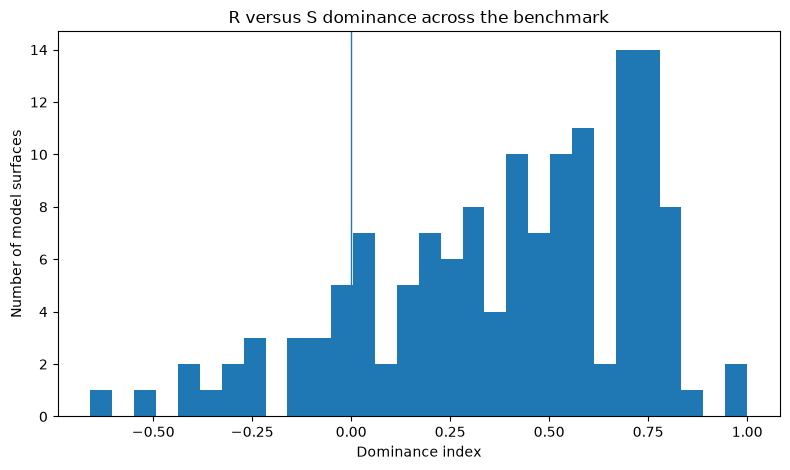

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(
    surface_dominance["dominance_index"].dropna(),
    bins=30,
)
ax.axvline(0, linewidth=1)
ax.set_xlabel("Dominance index")
ax.set_ylabel("Number of model surfaces")
ax.set_title("R versus S dominance across the benchmark")
plt.tight_layout()
plt.show()

# 4. Sensitivity of dominance classification to the cutoff

A classification cutoff is descriptive, so evaluate several.

For cutoff `c`:

- `D > c`: R-dominant;
- `D < -c`: S-dominant;
- otherwise balanced.

In [7]:
def classify_dominance(d, cutoff=0.25):
    if pd.isna(d):
        return np.nan
    if d > cutoff:
        return "R_dominant"
    if d < -cutoff:
        return "S_dominant"
    return "balanced"

cutoff_rows = []

for cutoff in [0.10, 0.20, 0.25, 0.33]:
    cls = surface_dominance["dominance_index"].map(
        lambda x: classify_dominance(x, cutoff)
    )

    freq = cls.value_counts(normalize=True)

    cutoff_rows.append(
        {
            "cutoff": cutoff,
            "R_dominant": freq.get("R_dominant", 0.0),
            "balanced": freq.get("balanced", 0.0),
            "S_dominant": freq.get("S_dominant", 0.0),
        }
    )

cutoff_summary = pd.DataFrame(cutoff_rows)
display(cutoff_summary)

DOMINANCE_CUTOFF = 0.25

surface_dominance["dominance_class"] = (
    surface_dominance["dominance_index"]
    .map(lambda x: classify_dominance(x, DOMINANCE_CUTOFF))
)

display(
    surface_dominance["dominance_class"]
    .value_counts(normalize=True)
    .rename("fraction")
    .to_frame()
)

,cutoff,R_dominant,balanced,S_dominant
0,0.10,0.784173,0.122302,0.093525
1,0.20,0.733813,0.194245,0.071942
2,0.25,0.669065,0.280576,0.050360
3,0.33,0.597122,0.374101,0.028777


,fraction
dominance_class,
R_dominant,0.669065
balanced,0.280576
S_dominant,0.050360


## 5. Dominance by biological task

In [8]:
task_dominance = (
    surface_dominance.groupby("task")
    .agg(
        median_R_effect=("R_effect_abs_median", "median"),
        median_S_effect=("S_effect_abs_median", "median"),
        median_D=("dominance_index", "median"),
        mean_D=("dominance_index", "mean"),
        R_dominant_fraction=(
            "dominance_class",
            lambda x: (x == "R_dominant").mean(),
        ),
        balanced_fraction=(
            "dominance_class",
            lambda x: (x == "balanced").mean(),
        ),
        S_dominant_fraction=(
            "dominance_class",
            lambda x: (x == "S_dominant").mean(),
        ),
    )
    .sort_values("median_D", ascending=False)
)

display(task_dominance)

,median_R_effect,median_S_effect,median_D,mean_D,R_dominant_fraction,balanced_fraction,S_dominant_fraction
task,,,,,,,
subtype_endolysin,0.147276,0.033332,0.649218,0.632067,1.00,0.00,0.00
global_easy,0.110931,0.022811,0.621234,0.576211,0.90,0.10,0.00
global_hard,0.051388,0.011964,0.579599,0.576993,0.95,0.05,0.00
global_mixed,0.109379,0.030533,0.550726,0.550607,1.00,0.00,0.00
subtype_depolymerase,0.040361,0.021488,0.239057,0.207682,0.50,0.40,0.10
multiclass_clean,0.029904,0.027370,0.068902,0.052242,0.10,0.70,0.20
subtype_val,0.136463,0.121854,-0.005681,0.093807,0.20,0.70,0.05


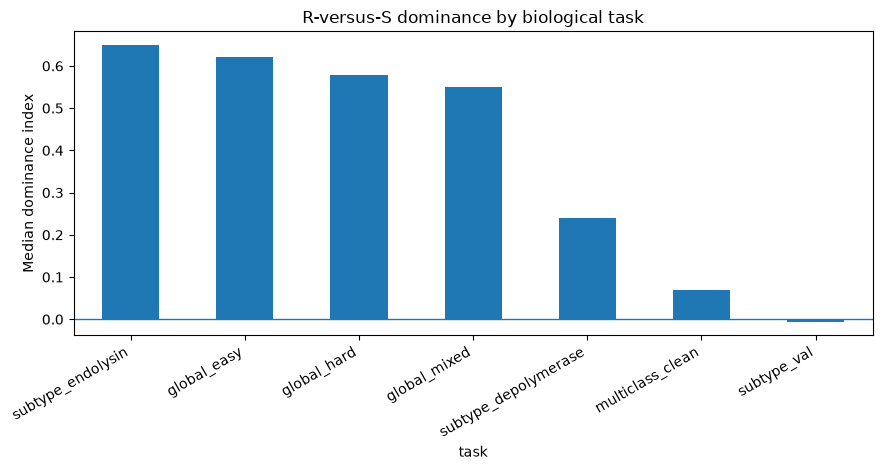

In [9]:
task_dominance["median_D"].plot(
    kind="bar",
    figsize=(9, 4.8),
)
plt.axhline(0, linewidth=1)
plt.ylabel("Median dominance index")
plt.title("R-versus-S dominance by biological task")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 6. Dominance by representation

In [10]:
rep_dominance = (
    surface_dominance.groupby("representation")
    .agg(
        median_R_effect=("R_effect_abs_median", "median"),
        median_S_effect=("S_effect_abs_median", "median"),
        median_D=("dominance_index", "median"),
        mean_D=("dominance_index", "mean"),
        R_dominant_fraction=(
            "dominance_class",
            lambda x: (x == "R_dominant").mean(),
        ),
        balanced_fraction=(
            "dominance_class",
            lambda x: (x == "balanced").mean(),
        ),
        S_dominant_fraction=(
            "dominance_class",
            lambda x: (x == "S_dominant").mean(),
        ),
    )
    .sort_values("median_D", ascending=False)
)

display(rep_dominance)

,median_R_effect,median_S_effect,median_D,mean_D,R_dominant_fraction,balanced_fraction,S_dominant_fraction
representation,,,,,,,
esm2_t30_150m,0.062305,0.016947,0.670859,0.455976,0.685714,0.257143,0.057143
esm2_t6_8m,0.098084,0.019457,0.548388,0.400909,0.685714,0.257143,0.057143
roxy_48,0.091551,0.032453,0.397607,0.360375,0.685714,0.314286,0.000000
onehot_1024,0.115912,0.050639,0.394636,0.326303,0.600000,0.285714,0.085714


## 7. Dominance by learner

In [11]:
alg_dominance = (
    surface_dominance.groupby("algorithm")
    .agg(
        median_R_effect=("R_effect_abs_median", "median"),
        median_S_effect=("S_effect_abs_median", "median"),
        median_D=("dominance_index", "median"),
        mean_D=("dominance_index", "mean"),
        R_dominant_fraction=(
            "dominance_class",
            lambda x: (x == "R_dominant").mean(),
        ),
        balanced_fraction=(
            "dominance_class",
            lambda x: (x == "balanced").mean(),
        ),
        S_dominant_fraction=(
            "dominance_class",
            lambda x: (x == "S_dominant").mean(),
        ),
    )
    .sort_values("median_D", ascending=False)
)

display(alg_dominance)

,median_R_effect,median_S_effect,median_D,mean_D,R_dominant_fraction,balanced_fraction,S_dominant_fraction
algorithm,,,,,,,
MLP,0.074426,0.026341,0.520023,0.389819,0.642857,0.250000,0.107143
XGB,0.084253,0.027825,0.465502,0.398785,0.642857,0.357143,0.000000
RF,0.106924,0.022075,0.457333,0.400834,0.678571,0.250000,0.035714
LR,0.064310,0.022371,0.434458,0.379043,0.714286,0.214286,0.071429
KNN,0.095468,0.035282,0.396113,0.363633,0.642857,0.321429,0.035714


# 8. Independent dominance check from factorial variance decomposition

The RQ4 4×4 decomposition allows a second definition:

\[
D_{SS}
=
\frac{SS_R-SS_S}{SS_R+SS_S}.
\]

Interaction is deliberately excluded from the denominator here because the question is **which main effect dominates when the non-additive component is set aside**.

In [12]:
decomp_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "algorithm"]
):
    task, rep, alg = keys

    surface = (
        grp.pivot_table(
            index="R",
            columns="S",
            values="mcc",
            aggfunc="first",
        )
        .reindex(index=R_LEVELS, columns=S_LEVELS)
    )

    if surface.isna().any().any():
        continue

    x = surface.to_numpy(float)
    grand = x.mean()
    r_eff = x.mean(axis=1) - grand
    s_eff = x.mean(axis=0) - grand
    additive = grand + r_eff[:, None] + s_eff[None, :]
    resid = x - additive

    ss_R = len(S_LEVELS) * np.sum(r_eff ** 2)
    ss_S = len(R_LEVELS) * np.sum(s_eff ** 2)
    ss_I = np.sum(resid ** 2)
    ss_total = np.sum((x - grand) ** 2)

    decomp_rows.append(
        {
            "task": task,
            "representation": rep,
            "algorithm": alg,
            "ss_R": ss_R,
            "ss_S": ss_S,
            "ss_interaction": ss_I,
            "fraction_R": ss_R / ss_total if ss_total > 0 else np.nan,
            "fraction_S": ss_S / ss_total if ss_total > 0 else np.nan,
            "fraction_interaction": (
                ss_I / ss_total if ss_total > 0 else np.nan
            ),
            "SS_dominance_index": (
                (ss_R - ss_S) / (ss_R + ss_S)
                if (ss_R + ss_S) > 0
                else np.nan
            ),
            "log10_SS_R_over_S": (
                np.log10(ss_R / ss_S)
                if ss_R > 0 and ss_S > 0
                else np.nan
            ),
        }
    )

factorial_dominance = pd.DataFrame(decomp_rows)

dominance_compare = surface_dominance.merge(
    factorial_dominance,
    on=["task", "representation", "algorithm"],
    how="inner",
    validate="one_to_one",
)

print(
    "Spearman between extreme-span D and SS-based D:",
    dominance_compare[
        ["dominance_index", "SS_dominance_index"]
    ]
    .corr(method="spearman")
    .iloc[0, 1],
)

display(
    dominance_compare[
        [
            "dominance_index",
            "SS_dominance_index",
            "fraction_R",
            "fraction_S",
            "fraction_interaction",
        ]
    ].describe()
)

Spearman between extreme-span D and SS-based D: 0.7896822914339336


,dominance_index,SS_dominance_index,fraction_R,fraction_S,fraction_interaction
count,139.000000,140.000000,140.000000,140.000000,140.000000
mean,0.386319,0.567560,0.608916,0.124405,0.266679
std,0.341339,0.440225,0.290394,0.113455,0.223039
min,-0.658486,-0.948935,0.016155,0.002045,0.013245
25%,0.173140,0.312905,0.316220,0.036377,0.068462
50%,0.446735,0.752170,0.705293,0.091297,0.183435
75%,0.674410,0.907186,0.872300,0.194841,0.408318
max,1.000000,0.995427,0.983547,0.616557,0.823608


# 9. Does the dominant factor depend on where the other factor is fixed?

This is the key regime-dependence analysis.

At each matched stringency level `L ∈ {90,70,50,30}` compare:

\[
|R90\to R30|\; \text{at}\; S=L
\]

against:

\[
|S90\to S30|\; \text{at}\; R=L.
\]

Define:

\[
D_L=
\frac{|E_R(L)|-|E_S(L)|}
{|E_R(L)|+|E_S(L)|}.
\]

If `D_L` changes sign across L, then the apparent “dominant factor” flips within the same model surface.

In [13]:
regime_rows = []

for _, row in surface_dominance.iterrows():
    base = {
        "task": row["task"],
        "representation": row["representation"],
        "algorithm": row["algorithm"],
    }

    for level in [90, 70, 50, 30]:
        r_eff = row[f"R_effect_at_S{level}"]
        s_eff = row[f"S_effect_at_R{level}"]

        denom = abs(r_eff) + abs(s_eff)
        d = (
            (abs(r_eff) - abs(s_eff)) / denom
            if denom > 0
            else np.nan
        )

        regime_rows.append(
            {
                **base,
                "matched_level": level,
                "R_effect": r_eff,
                "S_effect": s_eff,
                "R_abs": abs(r_eff),
                "S_abs": abs(s_eff),
                "dominance_index": d,
                "dominance_class": classify_dominance(
                    d,
                    DOMINANCE_CUTOFF,
                ),
            }
        )

regime_dominance = pd.DataFrame(regime_rows)

display(
    regime_dominance.groupby("matched_level")
    .agg(
        median_R_abs=("R_abs", "median"),
        median_S_abs=("S_abs", "median"),
        median_D=("dominance_index", "median"),
        R_dominant_fraction=(
            "dominance_class",
            lambda x: (x == "R_dominant").mean(),
        ),
        balanced_fraction=(
            "dominance_class",
            lambda x: (x == "balanced").mean(),
        ),
        S_dominant_fraction=(
            "dominance_class",
            lambda x: (x == "S_dominant").mean(),
        ),
    )
    .reindex(R_LEVELS)
)

,median_R_abs,median_S_abs,median_D,R_dominant_fraction,balanced_fraction,S_dominant_fraction
matched_level,,,,,,
90,0.087235,0.048235,0.283823,0.535714,0.285714,0.178571
70,0.093130,0.031056,0.472981,0.657143,0.142857,0.192857
50,0.081692,0.017602,0.621479,0.742857,0.157143,0.092857
30,0.064053,0.013646,0.667776,0.778571,0.107143,0.078571


## 10. How often does dominance flip within the same surface?

In [14]:
flip_rows = []

for keys, grp in regime_dominance.groupby(
    ["task", "representation", "algorithm"]
):
    task, rep, alg = keys

    ordered = (
        grp.set_index("matched_level")
        .reindex(R_LEVELS)
    )

    signs = np.sign(
        ordered["dominance_index"].to_numpy(float)
    )

    finite_signs = signs[np.isfinite(signs)]

    has_positive = np.any(finite_signs > 0)
    has_negative = np.any(finite_signs < 0)

    flip_rows.append(
        {
            "task": task,
            "representation": rep,
            "algorithm": alg,
            "D90": ordered.loc[90, "dominance_index"],
            "D70": ordered.loc[70, "dominance_index"],
            "D50": ordered.loc[50, "dominance_index"],
            "D30": ordered.loc[30, "dominance_index"],
            "sign_flip_any": bool(has_positive and has_negative),
            "class_flip_R90_to_R30": (
                ordered.loc[90, "dominance_class"]
                != ordered.loc[30, "dominance_class"]
            ),
        }
    )

dominance_flips = pd.DataFrame(flip_rows)

print(
    "Any sign flip within surface:",
    dominance_flips["sign_flip_any"].mean(),
)

print(
    "Class flip between matched 90 and 30:",
    dominance_flips["class_flip_R90_to_R30"].mean(),
)

display(
    dominance_flips.groupby("task")[
        ["sign_flip_any", "class_flip_R90_to_R30"]
    ].mean()
)

Any sign flip within surface: 0.4142857142857143
Class flip between matched 90 and 30: 0.42857142857142855


,sign_flip_any,class_flip_R90_to_R30
task,,
global_easy,0.05,0.25
global_hard,0.30,0.40
global_mixed,0.00,0.10
multiclass_clean,0.85,0.60
subtype_depolymerase,0.80,0.60
subtype_endolysin,0.00,0.05
subtype_val,0.90,1.00


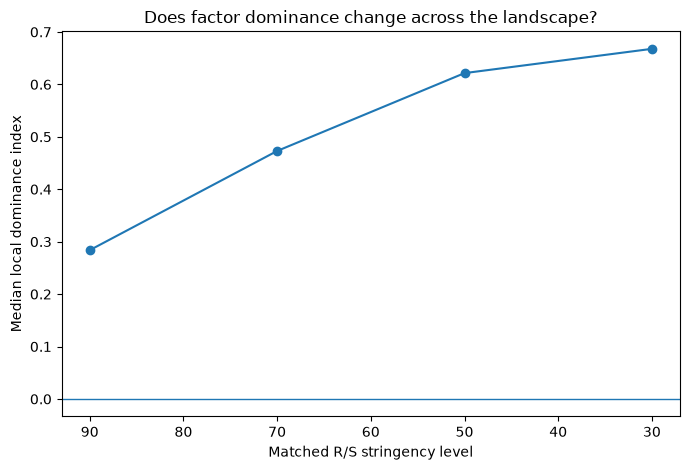

In [15]:
median_regime_D = (
    regime_dominance.groupby("matched_level")[
        "dominance_index"
    ]
    .median()
    .reindex(R_LEVELS)
)

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.plot(
    R_LEVELS,
    median_regime_D,
    marker="o",
)
ax.axhline(0, linewidth=1)
ax.set_xlabel("Matched R/S stringency level")
ax.set_ylabel("Median local dominance index")
ax.set_title("Does factor dominance change across the landscape?")
ax.invert_xaxis()
plt.tight_layout()
plt.show()

# 11. Local edge dominance across the 3×3 transition grid

For each surface and each adjacent `(R step, S step)` pair, compare the magnitude of:

- the local R edge at the loose S side;
- the local S edge at the loose R side.

This maps whether local movement through the generalization landscape is primarily R-driven or S-driven.

In [16]:
local_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "algorithm"]
):
    task, rep, alg = keys

    lookup = {
        (int(r), int(s)): float(m)
        for r, s, m in zip(
            grp["R"],
            grp["S"],
            grp["mcc"],
        )
    }

    for r0, r1 in ADJ_R_PAIRS:
        for s0, s1 in ADJ_S_PAIRS:
            dR = lookup[(r1, s0)] - lookup[(r0, s0)]
            dS = lookup[(r0, s1)] - lookup[(r0, s0)]

            denom = abs(dR) + abs(dS)
            d = (
                (abs(dR) - abs(dS)) / denom
                if denom > 0
                else np.nan
            )

            local_rows.append(
                {
                    "task": task,
                    "representation": rep,
                    "algorithm": alg,
                    "R_step": f"R{r0}→R{r1}",
                    "S_step": f"S{s0}→S{s1}",
                    "delta_R_local": dR,
                    "delta_S_local": dS,
                    "dominance_index": d,
                    "dominance_class": classify_dominance(
                        d,
                        DOMINANCE_CUTOFF,
                    ),
                }
            )

local_dominance = pd.DataFrame(local_rows)

local_map = (
    local_dominance.groupby(["R_step", "S_step"])[
        "dominance_index"
    ]
    .median()
    .unstack()
    .reindex(
        index=["R90→R70", "R70→R50", "R50→R30"],
        columns=["S90→S70", "S70→S50", "S50→S30"],
    )
)

display(local_map)

S_step,S90→S70,S70→S50,S50→S30
R_step,,,
R90→R70,0.273907,0.046215,0.123875
R70→R50,0.545403,0.260289,0.002835
R50→R30,0.442331,0.469675,0.278532


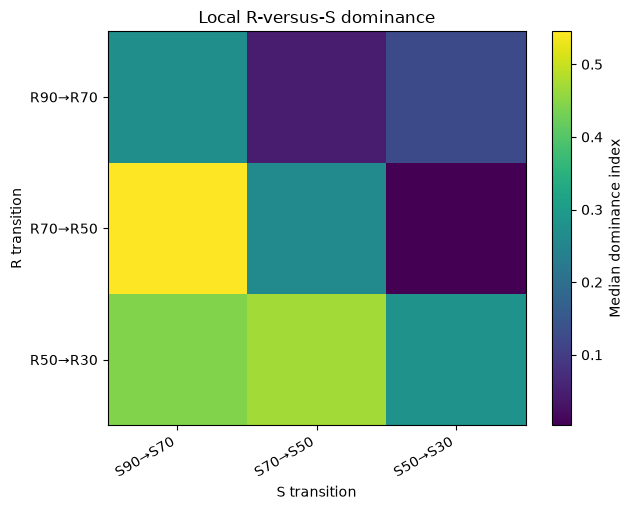

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(local_map.to_numpy(), aspect="auto")

ax.set_xticks(
    range(len(local_map.columns)),
    local_map.columns,
    rotation=30,
    ha="right",
)
ax.set_yticks(
    range(len(local_map.index)),
    local_map.index,
)
ax.set_xlabel("S transition")
ax.set_ylabel("R transition")
ax.set_title("Local R-versus-S dominance")
plt.colorbar(im, ax=ax, label="Median dominance index")
plt.tight_layout()
plt.show()

# 12. Dominance map: task × representation

This identifies whether representation changes not only robustness but **which protocol factor is the primary source of degradation**.

,task,representation,median_D,median_R_effect,median_S_effect,R_dominant_fraction,S_dominant_fraction
0,global_easy,esm2_t30_150m,0.766246,0.072177,0.012461,1.0,0.0
1,global_easy,esm2_t6_8m,0.762063,0.108505,0.013133,1.0,0.0
2,global_easy,onehot_1024,0.340560,0.126688,0.066146,0.8,0.0
3,global_easy,roxy_48,0.547433,0.121933,0.037233,0.8,0.0
4,global_hard,esm2_t30_150m,0.718669,0.049656,0.008413,1.0,0.0
5,global_hard,esm2_t6_8m,0.671258,0.038021,0.009064,1.0,0.0
6,global_hard,onehot_1024,0.532341,0.059478,0.021155,0.8,0.0
7,global_hard,roxy_48,0.464542,0.061607,0.026280,1.0,0.0
8,global_mixed,esm2_t30_150m,0.686136,0.080363,0.018337,1.0,0.0
9,global_mixed,esm2_t6_8m,0.673945,0.101580,0.019387,1.0,0.0


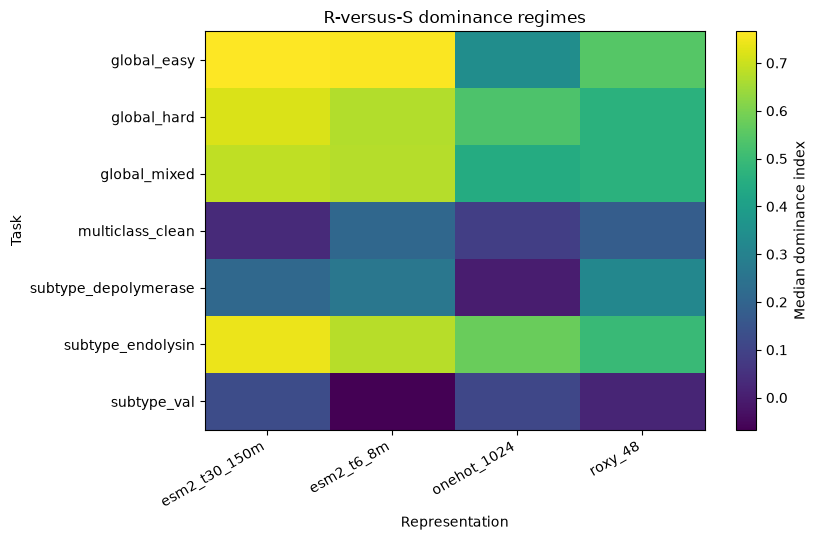

In [18]:
task_rep_dom = (
    surface_dominance.groupby(
        ["task", "representation"]
    )
    .agg(
        median_D=("dominance_index", "median"),
        median_R_effect=("R_effect_abs_median", "median"),
        median_S_effect=("S_effect_abs_median", "median"),
        R_dominant_fraction=(
            "dominance_class",
            lambda x: (x == "R_dominant").mean(),
        ),
        S_dominant_fraction=(
            "dominance_class",
            lambda x: (x == "S_dominant").mean(),
        ),
    )
    .reset_index()
)

display(task_rep_dom)

pivot = task_rep_dom.pivot(
    index="task",
    columns="representation",
    values="median_D",
)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
im = ax.imshow(pivot.to_numpy(), aspect="auto")

ax.set_xticks(
    range(len(pivot.columns)),
    pivot.columns,
    rotation=30,
    ha="right",
)
ax.set_yticks(
    range(len(pivot.index)),
    pivot.index,
)
ax.set_xlabel("Representation")
ax.set_ylabel("Task")
ax.set_title("R-versus-S dominance regimes")
plt.colorbar(im, ax=ax, label="Median dominance index")
plt.tight_layout()
plt.show()

# 13. Reconstruct training-data quantity and split topology

RQ5 needs to distinguish two different protocol perturbations:

### R axis
Changes the amount of available non-redundant training evidence.

### S axis
At fixed R, should leave the universe approximately constant while changing cluster granularity and train/test topology.

Use the previously generated RQ2/RQ3 caches when available. Otherwise reconstruct from the frozen predictive-universe files.

In [19]:
RQ2_STATE_CACHE = CACHE_DIR / "rq2v2_evidence_state.tsv"
RQ3_TOPOLOGY_CACHE = CACHE_DIR / "rq3_split_topology.tsv"

def infer_split_column(df):
    for c in ["split", "outer_split", "partition", "set"]:
        if c in df.columns:
            return c
    raise KeyError(f"No split column found. Columns: {list(df.columns)}")

def infer_cluster_column(df):
    for c in ["cluster_id", "mmseqs_cluster_id", "cluster"]:
        if c in df.columns:
            return c
    raise KeyError(f"No cluster column found. Columns: {list(df.columns)}")

def reconstruct_topology():
    rows = []

    for task, task_path in TASK_PATHS.items():
        for r in R_LEVELS:
            for s in S_LEVELS:
                path = (
                    PREDICTIVE_ROOT
                    / task_path
                    / f"R{r}_S{s}"
                    / "eligible_entities.tsv.gz"
                )

                if not path.is_file():
                    rows.append(
                        {
                            "task": task,
                            "R": r,
                            "S": s,
                            "found": False,
                        }
                    )
                    continue

                df = pd.read_csv(
                    path,
                    sep="\t",
                    low_memory=False,
                )

                split_col = infer_split_column(df)
                cluster_col = infer_cluster_column(df)

                split = df[split_col].astype(str).str.lower()
                train = split.eq("train")
                test = split.eq("test")

                n_train = int(train.sum())
                n_test = int(test.sum())

                n_clusters_total = int(df[cluster_col].nunique())
                n_clusters_train = int(
                    df.loc[train, cluster_col].nunique()
                )
                n_clusters_test = int(
                    df.loc[test, cluster_col].nunique()
                )

                rows.append(
                    {
                        "task": task,
                        "R": r,
                        "S": s,
                        "found": True,
                        "n_total": len(df),
                        "n_train": n_train,
                        "n_test": n_test,
                        "test_fraction": n_test / len(df),
                        "n_clusters_total": n_clusters_total,
                        "n_clusters_train": n_clusters_train,
                        "n_clusters_test": n_clusters_test,
                        "entities_per_cluster_total": (
                            len(df) / n_clusters_total
                            if n_clusters_total > 0
                            else np.nan
                        ),
                        "entities_per_train_cluster": (
                            n_train / n_clusters_train
                            if n_clusters_train > 0
                            else np.nan
                        ),
                    }
                )

    return pd.DataFrame(rows)

if RQ3_TOPOLOGY_CACHE.is_file():
    topology = pd.read_csv(
        RQ3_TOPOLOGY_CACHE,
        sep="\t",
        low_memory=False,
    )
    print("Loaded RQ3 topology cache.")
else:
    topology = reconstruct_topology()
    topology.to_csv(
        RQ3_TOPOLOGY_CACHE,
        sep="\t",
        index=False,
    )
    print("Reconstructed topology.")

print("Topology cells:", len(topology))
display(topology.head())

Loaded RQ3 topology cache.
Topology cells: 112


,task,R,S,found,n_total,n_train,n_test,test_fraction,n_clusters_total,n_clusters_train,n_clusters_test,entities_per_cluster_total,entities_per_train_cluster,entities_per_test_cluster,n_positive_train,n_positive_test,test_prevalence_from_universe
0,global_easy,90,90,True,30092,21049,9043,0.300512,30083,21041,9042,1.000299,1.000380,1.000111,3324.0,1439.0,0.159129
1,global_easy,90,70,True,30092,21050,9042,0.300479,21485,15029,6456,1.400605,1.400625,1.400558,3321.0,1442.0,0.159478
2,global_easy,90,50,True,30092,21068,9024,0.299880,14786,10284,4502,2.035168,2.048619,2.004442,3380.0,1383.0,0.153258
3,global_easy,90,30,True,30092,21076,9016,0.299615,8995,6238,2757,3.345414,3.378647,3.270221,3284.0,1479.0,0.164042
4,global_easy,70,90,True,21512,15058,6454,0.300019,21507,15055,6452,1.000232,1.000199,1.000310,2437.0,1026.0,0.158971


## 14. Quantify how strongly R and S perturb training-set size

In [20]:
size_by_R = (
    topology.groupby("R")
    .agg(
        median_n_train=("n_train", "median"),
        median_n_test=("n_test", "median"),
        median_test_fraction=("test_fraction", "median"),
    )
    .reindex(R_LEVELS)
)

size_by_S = (
    topology.groupby("S")
    .agg(
        median_n_train=("n_train", "median"),
        median_n_test=("n_test", "median"),
        median_test_fraction=("test_fraction", "median"),
    )
    .reindex(S_LEVELS)
)

print("By R")
display(size_by_R)

print("By S")
display(size_by_S)

By R


,median_n_train,median_n_test,median_test_fraction
R,,,
90,19377.5,8302.5,0.300211
70,13931.0,5960.0,0.299799
50,9694.0,4145.0,0.299882
30,5987.0,2565.0,0.299965


By S


,median_n_train,median_n_test,median_test_fraction
S,,,
90,9582.0,4104.0,0.299985
70,9579.0,4107.0,0.300188
50,9582.0,4104.0,0.299978
30,9599.5,4086.5,0.299622


### Relative span in train size

For each `task × conditioning factor`, compare loose versus strict levels.

This makes explicit that R and S perturb the benchmark through very different mechanisms.

In [21]:
quantity_span_rows = []

for task, grp in topology.groupby("task"):
    for s in S_LEVELS:
        x = grp[grp["S"].eq(s)].set_index("R")
        if {90, 30} <= set(x.index):
            n90 = float(x.loc[90, "n_train"])
            n30 = float(x.loc[30, "n_train"])

            quantity_span_rows.append(
                {
                    "task": task,
                    "axis": "R",
                    "conditioning_level": s,
                    "relative_train_change": (
                        (n30 - n90) / n90
                        if n90 > 0
                        else np.nan
                    ),
                }
            )

    for r in R_LEVELS:
        x = grp[grp["R"].eq(r)].set_index("S")
        if {90, 30} <= set(x.index):
            n90 = float(x.loc[90, "n_train"])
            n30 = float(x.loc[30, "n_train"])

            quantity_span_rows.append(
                {
                    "task": task,
                    "axis": "S",
                    "conditioning_level": r,
                    "relative_train_change": (
                        (n30 - n90) / n90
                        if n90 > 0
                        else np.nan
                    ),
                }
            )

quantity_span = pd.DataFrame(quantity_span_rows)

display(
    quantity_span.groupby("axis")[
        "relative_train_change"
    ].agg(["mean", "median", "std", "min", "max"])
)

,mean,median,std,min,max
axis,,,,,
R,-0.679748,-0.692519,0.026902,-0.701886,-0.626940
S,0.001092,0.000456,0.003115,-0.004308,0.011029


# 15. R effect per amount of training evidence removed

For R we can calculate a valid descriptive normalization:

\[
L_R=
\frac{-\Delta MCC_R}
{\text{fraction of train entities removed}}
\times0.10.
\]

This asks how much MCC changes per 10% reduction in train entities.

It does **not** estimate a causal sample-size effect because changing R also changes sequence redundancy structure.

In [22]:
mcc_r = r_deltas[
    r_deltas["metric"].eq("mcc")
].copy()

r_entity_rows = []

for task, grp in topology.groupby("task"):
    for s in S_LEVELS:
        g = grp[grp["S"].eq(s)].set_index("R")

        for r0, r1 in R_PAIRS:
            if r0 not in g.index or r1 not in g.index:
                continue

            n0 = float(g.loc[r0, "n_train"])
            n1 = float(g.loc[r1, "n_train"])

            r_entity_rows.append(
                {
                    "task": task,
                    "S_fixed": s,
                    "R_from": r0,
                    "R_to": r1,
                    "fraction_train_removed": (
                        (n0 - n1) / n0
                        if n0 > 0
                        else np.nan
                    ),
                }
            )

r_entity_change = pd.DataFrame(r_entity_rows)

r_quantity = mcc_r.merge(
    r_entity_change,
    on=[
        "task",
        "S_fixed",
        "R_from",
        "R_to",
    ],
    how="left",
    validate="many_to_one",
)

r_quantity["mcc_loss"] = -r_quantity["delta"]

r_quantity["mcc_loss_per_10pct_removed"] = np.where(
    r_quantity["fraction_train_removed"] > 0,
    r_quantity["mcc_loss"]
    / r_quantity["fraction_train_removed"]
    * 0.10,
    np.nan,
)

display(
    r_quantity[
        r_quantity["R_from"].eq(90)
        & r_quantity["R_to"].eq(30)
    ]
    .groupby("representation")[
        "mcc_loss_per_10pct_removed"
    ]
    .agg(["mean", "median", "std", "min", "max"])
)

,mean,median,std,min,max
representation,,,,,
esm2_t30_150m,0.007453,0.008560,0.009190,-0.025402,0.039921
esm2_t6_8m,0.007508,0.008794,0.015385,-0.073844,0.041852
onehot_1024,0.017675,0.014020,0.018666,-0.026423,0.073682
roxy_48,0.009963,0.011479,0.014139,-0.034480,0.071352


# 16. How much of R sensitivity is associated with data quantity?

For each `task × representation × algorithm`, correlate local R-step MCC loss with the fraction of train entities removed.

Then summarize the distribution of correlations.

A weak global association means that **quantity alone is insufficient to explain R sensitivity**, not that sample size is irrelevant.

In [23]:
r_step_quantity = r_quantity[
    r_quantity.apply(
        lambda x: (
            int(x["R_from"]),
            int(x["R_to"]),
        ) in ADJ_R_PAIRS,
        axis=1,
    )
].copy()

quantity_corr_rows = []

for keys, grp in r_step_quantity.groupby(
    ["task", "representation", "algorithm"]
):
    task, rep, alg = keys

    x = grp[
        ["fraction_train_removed", "mcc_loss"]
    ].dropna()

    rho = (
        x["fraction_train_removed"].corr(
            x["mcc_loss"],
            method="spearman",
        )
        if len(x) >= 4
        and x["fraction_train_removed"].nunique() > 1
        else np.nan
    )

    quantity_corr_rows.append(
        {
            "task": task,
            "representation": rep,
            "algorithm": alg,
            "n": len(x),
            "spearman_rho": rho,
        }
    )

r_quantity_correlations = pd.DataFrame(
    quantity_corr_rows
)

display(
    r_quantity_correlations["spearman_rho"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .to_frame("value")
)

,value
count,140.000000
mean,0.012220
median,0.010490
std,0.447305
min,-0.874126
max,0.972028


# 17. S effect versus split-topology change

S does not substantially reduce the biological universe. Its natural companion variable is therefore not sample-size loss but **cluster granularity**.

For each `task × R`, quantify S90→S30 changes in:

- train size;
- total cluster count;
- entities per cluster.

Then compare these changes with the magnitude of the native S effect.

In [24]:
s_topology_rows = []

for (task, r), grp in topology.groupby(["task", "R"]):
    g = grp.set_index("S")

    if not {90, 30} <= set(g.index):
        continue

    a = g.loc[90]
    b = g.loc[30]

    s_topology_rows.append(
        {
            "task": task,
            "R_fixed": r,
            "relative_train_change": (
                (b["n_train"] - a["n_train"])
                / a["n_train"]
                if a["n_train"] > 0
                else np.nan
            ),
            "cluster_count_ratio_S30_S90": (
                b["n_clusters_total"]
                / a["n_clusters_total"]
                if a["n_clusters_total"] > 0
                else np.nan
            ),
            "entities_per_cluster_ratio_S30_S90": (
                b["entities_per_cluster_total"]
                / a["entities_per_cluster_total"]
                if a["entities_per_cluster_total"] > 0
                else np.nan
            ),
        }
    )

s_topology_change = pd.DataFrame(s_topology_rows)

mcc_s = s_deltas[
    s_deltas["metric"].eq("mcc")
    & s_deltas["S_from"].eq(90)
    & s_deltas["S_to"].eq(30)
].copy()

s_topology_perf = mcc_s.merge(
    s_topology_change,
    on=["task", "R_fixed"],
    how="left",
    validate="many_to_one",
)

s_topology_perf["mcc_loss"] = -s_topology_perf["delta"]

display(
    s_topology_change[
        [
            "relative_train_change",
            "cluster_count_ratio_S30_S90",
            "entities_per_cluster_ratio_S30_S90",
        ]
    ].describe()
)

,relative_train_change,cluster_count_ratio_S30_S90,entities_per_cluster_ratio_S30_S90
count,28.000000,28.000000,28.000000
mean,0.001092,0.598737,1.998313
std,0.003115,0.261753,0.826545
min,-0.004308,0.299006,1.002010
25%,-0.000454,0.406213,1.317906
50%,0.000456,0.555999,1.815462
75%,0.001922,0.775930,2.469341
max,0.011029,0.997994,3.344414


## 18. Does S sensitivity track topology more than train-size drift?

In [25]:
s_corr_rows = []

for keys, grp in s_topology_perf.groupby(
    ["task", "representation", "algorithm"]
):
    task, rep, alg = keys

    for predictor in [
        "relative_train_change",
        "cluster_count_ratio_S30_S90",
        "entities_per_cluster_ratio_S30_S90",
    ]:
        x = grp[[predictor, "mcc_loss"]].dropna()

        rho = (
            x[predictor].corr(
                x["mcc_loss"],
                method="spearman",
            )
            if len(x) >= 4
            and x[predictor].nunique() > 1
            else np.nan
        )

        s_corr_rows.append(
            {
                "task": task,
                "representation": rep,
                "algorithm": alg,
                "predictor": predictor,
                "n": len(x),
                "spearman_rho": rho,
            }
        )

s_topology_correlations = pd.DataFrame(s_corr_rows)

display(
    s_topology_correlations.groupby("predictor")[
        "spearman_rho"
    ]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

,count,mean,median,std,min,max
predictor,,,,,,
cluster_count_ratio_S30_S90,140,-0.584927,-0.8,0.436049,-1.0,0.8
entities_per_cluster_ratio_S30_S90,140,0.584927,0.8,0.436049,-0.8,1.0
relative_train_change,140,-0.012876,0.0,0.586438,-1.0,1.0


# 19. Dominance with AP skill

If R dominance is only an MCC/threshold phenomenon, it should weaken strongly with ranking-based metrics.

Recalculate the surface-level dominance index using AP skill for binary tasks.

In [26]:
def build_metric_dominance(
    df,
    metric,
    tasks=None,
):
    rows = []

    work = df.copy()

    if tasks is not None:
        work = work[work["task"].isin(tasks)]

    for keys, grp in work.groupby(
        ["task", "representation", "algorithm"]
    ):
        task, rep, alg = keys

        surface = (
            grp.pivot_table(
                index="R",
                columns="S",
                values=metric,
                aggfunc="first",
            )
            .reindex(index=R_LEVELS, columns=S_LEVELS)
        )

        if surface.isna().any().any():
            continue

        r_vals = [
            surface.loc[30, s] - surface.loc[90, s]
            for s in S_LEVELS
        ]

        s_vals = [
            surface.loc[r, 30] - surface.loc[r, 90]
            for r in R_LEVELS
        ]

        er = float(np.median(np.abs(r_vals)))
        es = float(np.median(np.abs(s_vals)))

        d = (
            (er - es) / (er + es)
            if (er + es) > 0
            else np.nan
        )

        rows.append(
            {
                "task": task,
                "representation": rep,
                "algorithm": alg,
                "metric": metric,
                "R_effect_abs_median": er,
                "S_effect_abs_median": es,
                "dominance_index": d,
            }
        )

    return pd.DataFrame(rows)

metric_dom_frames = [
    build_metric_dominance(master, "mcc")
]

if "ap_skill" in master.columns:
    metric_dom_frames.append(
        build_metric_dominance(
            master,
            "ap_skill",
            tasks=BINARY_TASKS,
        )
    )

if "macro_f1" in master.columns:
    metric_dom_frames.append(
        build_metric_dominance(
            master,
            "macro_f1",
            tasks=["multiclass_clean"],
        )
    )

metric_dominance = pd.concat(
    metric_dom_frames,
    ignore_index=True,
)

display(
    metric_dominance.groupby("metric")
    .agg(
        median_R_effect=("R_effect_abs_median", "median"),
        median_S_effect=("S_effect_abs_median", "median"),
        median_D=("dominance_index", "median"),
    )
)

,median_R_effect,median_S_effect,median_D
metric,,,
ap_skill,0.085256,0.030475,0.454285
macro_f1,0.046812,0.034747,0.035721
mcc,0.085105,0.025962,0.446735


In [27]:
wide_dom = metric_dominance.pivot_table(
    index=["task", "representation", "algorithm"],
    columns="metric",
    values="dominance_index",
    aggfunc="first",
)

if {"mcc", "ap_skill"} <= set(wide_dom.columns):
    x = wide_dom[["mcc", "ap_skill"]].dropna()

    print(
        "Spearman MCC-vs-APskill dominance:",
        x.corr(method="spearman").iloc[0, 1],
    )

    print(
        "Same sign:",
        (
            np.sign(x["mcc"])
            == np.sign(x["ap_skill"])
        ).mean(),
    )

Spearman MCC-vs-APskill dominance: 0.6959193847030337
Same sign: 0.8487394957983193


# 20. Which task × representation regimes are robustly R- or S-dominant?

Aggregate over algorithms and require directional consensus.

This is a more conservative regime map than simply looking at the median.

In [28]:
consensus_rows = []

for keys, grp in surface_dominance.groupby(
    ["task", "representation"]
):
    task, rep = keys

    d = grp["dominance_index"].dropna()

    consensus_rows.append(
        {
            "task": task,
            "representation": rep,
            "n_algorithms": len(d),
            "median_D": d.median(),
            "fraction_D_positive": (d > 0).mean(),
            "fraction_D_negative": (d < 0).mean(),
            "fraction_R_dominant": (
                grp["dominance_class"] == "R_dominant"
            ).mean(),
            "fraction_S_dominant": (
                grp["dominance_class"] == "S_dominant"
            ).mean(),
            "all_algorithms_same_sign": (
                (d > 0).all() or (d < 0).all()
            ),
        }
    )

task_rep_consensus = pd.DataFrame(
    consensus_rows
)

display(
    task_rep_consensus.sort_values(
        ["median_D"],
        ascending=False,
    )
)

,task,representation,n_algorithms,median_D,fraction_D_positive,fraction_D_negative,fraction_R_dominant,fraction_S_dominant,all_algorithms_same_sign
0,global_easy,esm2_t30_150m,5,0.766246,1.0,0.0,1.0,0.0,True
1,global_easy,esm2_t6_8m,5,0.762063,1.0,0.0,1.0,0.0,True
20,subtype_endolysin,esm2_t30_150m,5,0.742111,1.0,0.0,1.0,0.0,True
4,global_hard,esm2_t30_150m,5,0.718669,1.0,0.0,1.0,0.0,True
8,global_mixed,esm2_t30_150m,5,0.686136,1.0,0.0,1.0,0.0,True
21,subtype_endolysin,esm2_t6_8m,5,0.675719,1.0,0.0,1.0,0.0,True
9,global_mixed,esm2_t6_8m,5,0.673945,1.0,0.0,1.0,0.0,True
5,global_hard,esm2_t6_8m,5,0.671258,1.0,0.0,1.0,0.0,True
22,subtype_endolysin,onehot_1024,5,0.575373,1.0,0.0,1.0,0.0,True
3,global_easy,roxy_48,5,0.547433,1.0,0.0,0.8,0.0,True


# 21. Does representation strength reduce factor dominance?

A representation can be robust to both R and S while also producing a more balanced surface.

Compare:

- absolute R sensitivity;
- absolute S sensitivity;
- absolute dominance `|D|`.

A low `|D|` does not necessarily mean a good model; it means the two protocol factors contribute similarly.

In [29]:
rep_balance = (
    surface_dominance.groupby("representation")
    .agg(
        median_R_effect=("R_effect_abs_median", "median"),
        median_S_effect=("S_effect_abs_median", "median"),
        median_abs_D=(
            "dominance_index",
            lambda x: x.abs().median(),
        ),
        median_signed_D=("dominance_index", "median"),
    )
    .sort_values("median_R_effect", ascending=False)
)

display(rep_balance)

,median_R_effect,median_S_effect,median_abs_D,median_signed_D
representation,,,,
onehot_1024,0.115912,0.050639,0.406972,0.394636
esm2_t6_8m,0.098084,0.019457,0.548388,0.548388
roxy_48,0.091551,0.032453,0.397607,0.397607
esm2_t30_150m,0.062305,0.016947,0.670859,0.670859


# 22. A compact “driver map” for the manuscript

Classify each surface by:

### Dominant factor
R / balanced / S.

### Interaction burden
Using RQ4 factorial decomposition:

- low: interaction fraction < 0.10
- moderate: 0.10–0.25
- high: > 0.25.

This yields interpretable generalization regimes such as:

- `R-dominant / low-interaction`
- `R-dominant / high-interaction`
- `balanced / high-interaction`
- `S-dominant / moderate-interaction`

In [30]:
driver_map = dominance_compare.copy()

driver_map["dominant_factor"] = (
    driver_map["dominance_index"]
    .map(
        lambda x: classify_dominance(
            x,
            DOMINANCE_CUTOFF,
        )
    )
)

driver_map["interaction_burden"] = pd.cut(
    driver_map["fraction_interaction"],
    bins=[-np.inf, 0.10, 0.25, np.inf],
    labels=["low", "moderate", "high"],
)

driver_map["driver_regime"] = (
    driver_map["dominant_factor"].astype(str)
    + " / "
    + driver_map["interaction_burden"].astype(str)
)

display(
    driver_map["driver_regime"]
    .value_counts()
    .rename("n_surfaces")
    .to_frame()
)

,n_surfaces
driver_regime,
R_dominant / low,45
balanced / high,36
R_dominant / moderate,28
R_dominant / high,20
S_dominant / high,7
balanced / moderate,3


In [31]:
display(
    pd.crosstab(
        driver_map["task"],
        driver_map["driver_regime"],
        normalize="index",
    )
)

driver_regime,R_dominant / high,R_dominant / low,R_dominant / moderate,S_dominant / high,balanced / high,balanced / moderate
task,,,,,,
global_easy,0.000000,0.55,0.35,0.000000,0.050000,0.050000
global_hard,0.250000,0.20,0.50,0.000000,0.050000,0.000000
global_mixed,0.050000,0.65,0.30,0.000000,0.000000,0.000000
multiclass_clean,0.100000,0.00,0.00,0.200000,0.700000,0.000000
subtype_depolymerase,0.400000,0.05,0.05,0.100000,0.400000,0.000000
subtype_endolysin,0.000000,0.80,0.20,0.000000,0.000000,0.000000
subtype_val,0.210526,0.00,0.00,0.052632,0.631579,0.105263


# 23. RQ5 synthesis

After execution, RQ5 should answer:

1. Is R globally more influential than S?
2. By how much, using both extreme-span and SS-based definitions?
3. What fraction of model surfaces are R-dominant, balanced, or S-dominant?
4. Which biological tasks are consistently R-dominant?
5. Which tasks contain S-dominant or balanced regimes?
6. Does representation change which factor dominates?
7. Does learner choice change which factor dominates?
8. How often does dominance flip within the same surface as the matched R/S level changes?
9. Is local dominance concentrated in one part of the 3×3 transition map?
10. How much does R change train-data quantity?
11. How little does S change train/test size?
12. Does R performance loss scale with entity removal?
13. Does S loss track cluster granularity more than sample-size drift?
14. Is R/S dominance preserved in AP skill and macro-F1?
15. Which task×representation regimes show algorithm-level consensus?
16. How should the final manuscript distinguish:
    - evidence-removal effects,
    - remote-evaluation effects,
    - non-additive interactions?

In [32]:
rq5_rows = []

# Overall surface dominance.
rq5_rows.append(
    {
        "evidence": "surface_extreme_span_dominance",
        "group": "all",
        "n": len(surface_dominance),
        "median_R_effect_abs": surface_dominance[
            "R_effect_abs_median"
        ].median(),
        "median_S_effect_abs": surface_dominance[
            "S_effect_abs_median"
        ].median(),
        "median_dominance_index": surface_dominance[
            "dominance_index"
        ].median(),
        "R_dominant_fraction": (
            surface_dominance["dominance_class"]
            == "R_dominant"
        ).mean(),
        "balanced_fraction": (
            surface_dominance["dominance_class"]
            == "balanced"
        ).mean(),
        "S_dominant_fraction": (
            surface_dominance["dominance_class"]
            == "S_dominant"
        ).mean(),
    }
)

# Factorial main-effect dominance.
rq5_rows.append(
    {
        "evidence": "factorial_SS_dominance",
        "group": "all",
        "n": len(factorial_dominance),
        "median_fraction_R": factorial_dominance[
            "fraction_R"
        ].median(),
        "median_fraction_S": factorial_dominance[
            "fraction_S"
        ].median(),
        "median_fraction_interaction": factorial_dominance[
            "fraction_interaction"
        ].median(),
        "median_SS_dominance_index": factorial_dominance[
            "SS_dominance_index"
        ].median(),
    }
)

# Dominance flipping.
rq5_rows.append(
    {
        "evidence": "within_surface_dominance_flip",
        "group": "all",
        "n": len(dominance_flips),
        "any_sign_flip_fraction": dominance_flips[
            "sign_flip_any"
        ].mean(),
        "R90_to_R30_class_flip_fraction": dominance_flips[
            "class_flip_R90_to_R30"
        ].mean(),
    }
)

# Quantity perturbation.
for axis, grp in quantity_span.groupby("axis"):
    rq5_rows.append(
        {
            "evidence": "train_quantity_change",
            "group": axis,
            "n": len(grp),
            "median_relative_train_change": grp[
                "relative_train_change"
            ].median(),
            "mean_relative_train_change": grp[
                "relative_train_change"
            ].mean(),
        }
    )

rq5_summary = pd.DataFrame(rq5_rows)
display(rq5_summary)

SUMMARY_PATH = CACHE_DIR / "rq5_evidence_summary.tsv"
SURFACE_PATH = CACHE_DIR / "rq5_surface_dominance.tsv"
REGIME_PATH = CACHE_DIR / "rq5_matched_level_dominance.tsv"
FLIP_PATH = CACHE_DIR / "rq5_dominance_flips.tsv"
LOCAL_PATH = CACHE_DIR / "rq5_local_dominance.tsv"
FACTORIAL_PATH = CACHE_DIR / "rq5_factorial_dominance.tsv"
R_QUANTITY_PATH = CACHE_DIR / "rq5_R_quantity_normalization.tsv"
S_TOPOLOGY_PATH = CACHE_DIR / "rq5_S_topology_effects.tsv"
METRIC_PATH = CACHE_DIR / "rq5_metric_dominance.tsv"
DRIVER_PATH = CACHE_DIR / "rq5_driver_map.tsv"

rq5_summary.to_csv(SUMMARY_PATH, sep="\t", index=False)
surface_dominance.to_csv(SURFACE_PATH, sep="\t", index=False)
regime_dominance.to_csv(REGIME_PATH, sep="\t", index=False)
dominance_flips.to_csv(FLIP_PATH, sep="\t", index=False)
local_dominance.to_csv(LOCAL_PATH, sep="\t", index=False)
factorial_dominance.to_csv(FACTORIAL_PATH, sep="\t", index=False)
r_quantity.to_csv(R_QUANTITY_PATH, sep="\t", index=False)
s_topology_perf.to_csv(S_TOPOLOGY_PATH, sep="\t", index=False)
metric_dominance.to_csv(METRIC_PATH, sep="\t", index=False)
driver_map.to_csv(DRIVER_PATH, sep="\t", index=False)

print("Saved:")
for p in [
    SUMMARY_PATH,
    SURFACE_PATH,
    REGIME_PATH,
    FLIP_PATH,
    LOCAL_PATH,
    FACTORIAL_PATH,
    R_QUANTITY_PATH,
    S_TOPOLOGY_PATH,
    METRIC_PATH,
    DRIVER_PATH,
]:
    print(" ", p)

,evidence,group,n,median_R_effect_abs,median_S_effect_abs,median_dominance_index,R_dominant_fraction,balanced_fraction,S_dominant_fraction,median_fraction_R,median_fraction_S,median_fraction_interaction,median_SS_dominance_index,any_sign_flip_fraction,R90_to_R30_class_flip_fraction,median_relative_train_change,mean_relative_train_change
0,surface_extreme_span_dominance,all,140,0.085105,0.025962,0.446735,0.664286,0.278571,0.05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,factorial_SS_dominance,all,140,NaN,NaN,NaN,NaN,NaN,NaN,0.705293,0.091297,0.183435,0.75217,NaN,NaN,NaN,NaN
2,within_surface_dominance_flip,all,140,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.414286,0.428571,NaN,NaN
3,train_quantity_change,R,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.692519,-0.679748
4,train_quantity_change,S,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000456,0.001092


Saved:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq5_evidence_summary.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq5_surface_dominance.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq5_matched_level_dominance.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq5_dominance_flips.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq5_local_dominance.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq5_factorial_dominance.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis

## What this notebook should not conclude

Do not claim that R and S are biologically equivalent perturbations because their numeric thresholds use the same values.

Do not interpret R dominance as proof that sample size matters more than remote generalization. R changes **both quantity and redundancy structure**.

Do not interpret weak association between entity removal and MCC loss as proof that sample size is irrelevant.

Do not interpret S topology correlations causally; native S test populations change.

Do not collapse interaction into either R or S. The interaction is a third component of the generalization landscape.

The strongest defensible synthesis, if supported, is:

> **generalization is governed by a regime-dependent balance between evidence redundancy, train–test homology structure, and their interaction; the dominant source of apparent difficulty can change across the same factorial surface.**